# **TUẦN 43 - HOÀN TẤT HUẤN LUYỆN UNIFASHION + ATTENTION-GATED FUSION**
Xác minh checkpoint tốt nhất và xác minh kết quả huấn luyện đã có.

# **1 - Gắn Google Drive và tự phát hiện đường dẫn Tuần 41**

In [ ]:
from pathlib import Path
import unicodedata
from google.colab import drive

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/KHOALUAN')
week41_dirs = [p for p in ROOT.iterdir() if p.is_dir() and unicodedata.normalize('NFC',p.name) == 'Tuần 41']
assert len(week41_dirs) == 1, f'Cần đúng một thư mục Tuần 41, thấy: {week41_dirs}'
SOURCE = week41_dirs[0] / 'UniFashionResults_run2'
assert SOURCE.is_dir(), f'Không tìm thấy thư mục kết quả: {SOURCE}'
OUTPUT = ROOT / 'Tuần 43' / 'Week43_AttentionFusion_Completion_Evidence'
OUTPUT.mkdir(parents=True, exist_ok=True)
print('SOURCE ', SOURCE)
print('OUTPUT ', OUTPUT)
print('Chỉ đọc SOURCE, chỉ ghi vào OUTPUT')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SOURCE  /content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2
OUTPUT  /content/drive/MyDrive/KHOALUAN/Tuần 43/Week43_AttentionFusion_Completion_Evidence
Chỉ đọc SOURCE, chỉ ghi vào OUTPUT


# **2 - Đối chiếu trạng thái và metric đủ 10 epoch**

In [ ]:
import json
import pandas as pd
import numpy as np

status = json.loads((SOURCE/'status.json').read_text(encoding='utf-8'))
epochs = pd.read_csv(SOURCE/'epoch_metrics.csv')
assert set(['epoch','step','train_loss','monitor_loss']).issubset(epochs.columns)
assert len(epochs) == 10, f'Không đủ 10 epoch: {len(epochs)}'
assert epochs['epoch'].tolist() == list(range(1,11)), 'Thứ tự epoch không đúng 1..10'
assert epochs['step'].iloc[-1] == 90000, 'Bước huấn luyện cuối khác 90000'
assert np.isfinite(epochs[['train_loss','monitor_loss']].to_numpy()).all()
assert status.get('status') == 'completed', status
assert status.get('completed_epochs') == status.get('planned_epochs') == 10
assert status.get('optimizer_steps') == status.get('checkpoint_step') == 90000
best_row = epochs.loc[epochs['monitor_loss'].idxmin()]
assert np.isclose(float(best_row['monitor_loss']),float(status['best_monitor_loss']),rtol=1e-8,atol=1e-9)
print('STATUS ',status['status'])
print('EPOCHS ',len(epochs),'STEPS:',status['optimizer_steps'])
print('BEST MONITOR  epoch',int(best_row['epoch']),', loss',float(best_row['monitor_loss']))
print('EPOCH 10 ',epochs.tail(1).to_string(index=False))

STATUS  completed
EPOCHS  10 STEPS: 90000
BEST MONITOR  epoch 8 , loss 0.3128539915626377
EPOCH 10   epoch  step  train_samples  dropped_samples  monitor_samples  train_loss  train_loss_itc  train_loss_itm  train_loss_ttc  monitor_loss  monitor_loss_itc  monitor_loss_itm  monitor_loss_ttc
    10 90000          18000                0               96    0.131021        0.074137        0.029076        0.027809      0.351718          0.189184          0.159341          0.003194


# **3 - Vẽ lại biểu đồ loss, lưu minh chứng độc lập**

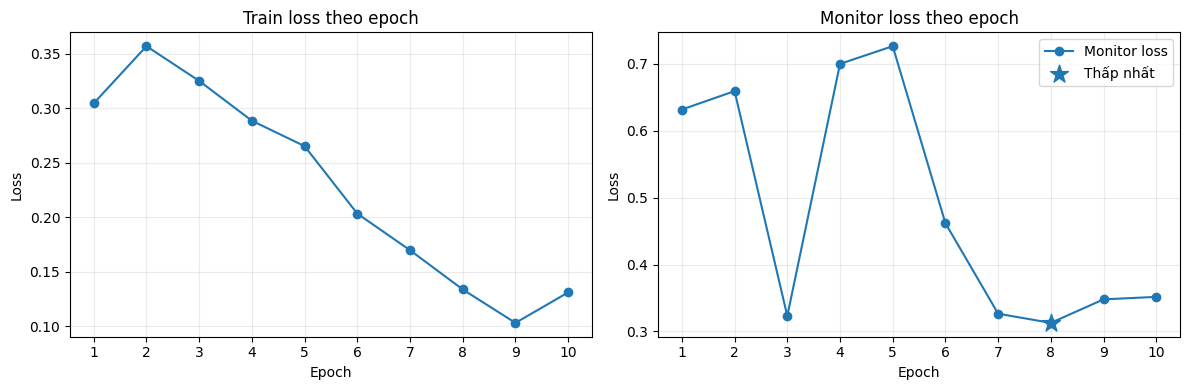

Đã lưu  /content/drive/MyDrive/KHOALUAN/Tuần 43/Week43_AttentionFusion_Completion_Evidence/week43_loss_by_epoch.png


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(epochs['epoch'], epochs['train_loss'], marker='o', label='Train loss trung bình')
ax[0].set(title='Train loss theo epoch', xlabel='Epoch', ylabel='Loss', xticks=range(1,11))
ax[0].grid(alpha=.25)
ax[1].plot(epochs['epoch'], epochs['monitor_loss'], marker='o', label='Monitor loss')
ax[1].scatter([int(best_row['epoch'])],[float(best_row['monitor_loss'])], marker='*', s=180, label='Thấp nhất')
ax[1].set(title='Monitor loss theo epoch', xlabel='Epoch', ylabel='Loss', xticks=range(1,11))
ax[1].grid(alpha=.25)
ax[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT/'week43_loss_by_epoch.png',dpi=160,bbox_inches='tight')
plt.show()
print('Đã lưu ',OUTPUT/'week43_loss_by_epoch.png')

# **4 - Kiểm tra hai checkpoint trên CPU**

In [ ]:
import torch, gc

def load_trusted_checkpoint(path):
    # Chỉ áp dụng cho checkpoint do chính bạn tạo hoặc nguồn tin cậy.
    return torch.load(path, map_location='cpu', weights_only=False, mmap=True)

last_path = SOURCE/'last.pt'
best_path = SOURCE/'best_monitor.pt'
assert last_path.is_file() and best_path.is_file(), 'Thiếu checkpoint trên Drive'

last = load_trusted_checkpoint(last_path)
assert isinstance(last,dict)
last_cursor = list(last.get('cursor',[]))
last_epoch_count = len(last.get('epochs',[]))
last_steps = len(last.get('history',[]))
assert last_cursor == [10,0], f'last.pt chưa ở cuối: {last_cursor}'
assert last_epoch_count == 10 and last_steps == 90000, (last_epoch_count,last_steps)
del last
gc.collect()

best = load_trusted_checkpoint(best_path)
assert isinstance(best,dict) and isinstance(best.get('model'),dict)
fusion_keys = sorted(k for k in best['model'] if k.startswith('attention_fusion.'))
assert len(fusion_keys) > 0, 'Không thấy tham số Attention-Gated Fusion trong best_monitor.pt'
assert int(best.get('epoch')) == int(best_row['epoch'])
assert np.isclose(float(best.get('monitor_loss')), float(best_row['monitor_loss']),rtol=1e-8,atol=1e-9)
checkpoint_audit = {
    'last_path':str(last_path), 'last_size_bytes':last_path.stat().st_size,
    'last_cursor':last_cursor, 'last_epochs':last_epoch_count, 'last_optimizer_steps':last_steps,
    'best_path':str(best_path), 'best_size_bytes':best_path.stat().st_size,
    'best_epoch':int(best.get('epoch')), 'best_monitor_loss':float(best.get('monitor_loss')),
    'fusion_parameter_key_count':len(fusion_keys), 'fusion_parameter_keys':fusion_keys,
    'checked_with':'torch.load(map_location=cpu, mmap=True); this is a metadata/state check, not a forward-pass evaluation'
}
del best
gc.collect()
(OUTPUT/'week43_checkpoint_audit.json').write_text(json.dumps(checkpoint_audit,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(checkpoint_audit,ensure_ascii=False,indent=2))

{
  "last_path": "/content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/last.pt",
  "last_size_bytes": 2350526301,
  "last_cursor": [
    10,
    0
  ],
  "last_epochs": 10,
  "last_optimizer_steps": 90000,
  "best_path": "/content/drive/MyDrive/KHOALUAN/Tuần 41/UniFashionResults_run2/best_monitor.pt",
  "best_size_bytes": 843297841,
  "best_epoch": 8,
  "best_monitor_loss": 0.31285399156263777,
  "fusion_parameter_key_count": 8,
  "fusion_parameter_keys": [
    "attention_fusion.gate_network.0.bias",
    "attention_fusion.gate_network.0.weight",
    "attention_fusion.gate_network.3.bias",
    "attention_fusion.gate_network.3.weight",
    "attention_fusion.projection.0.bias",
    "attention_fusion.projection.0.weight",
    "attention_fusion.projection.3.bias",
    "attention_fusion.projection.3.weight"
  ],
  "checked_with": "torch.load(map_location=cpu, mmap=True); this is a metadata/state check, not a forward-pass evaluation"
}
